# TP3 — Plus de deux réponses : reconnaître des chiffres
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- Passer de 2 à **10 classes** : sortie **softmax**, perte **sparse_categorical_crossentropy**
- Lire une **matrice de confusion à 10 classes**
- **Regarder les erreurs** du modèle pour les comprendre
- Utiliser des images comme entrée d'un réseau dense (en les aplatissant)

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`load_digits`  ·  `plt.imshow`  ·  `train_test_split`  ·  `LogisticRegression`  ·  `keras.Sequential`  ·  `layers.Dense`  ·  `softmax`  ·  `sparse_categorical_crossentropy`  ·  `np.argmax`  ·  `confusion_matrix`  ·  `np.where`  ·  `Counter`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Les données : des chiffres écrits à la main
1 797 images de **8 × 8 pixels**, chacune représentant un chiffre de 0 à 9. Chaque pixel va de 0 (blanc) à 16 (noir) : on divise par 16 pour avoir des valeurs entre 0 et 1, ce qui aide l'apprentissage. Un réseau dense attend un **vecteur** : 8 × 8 = **64 nombres** par image.

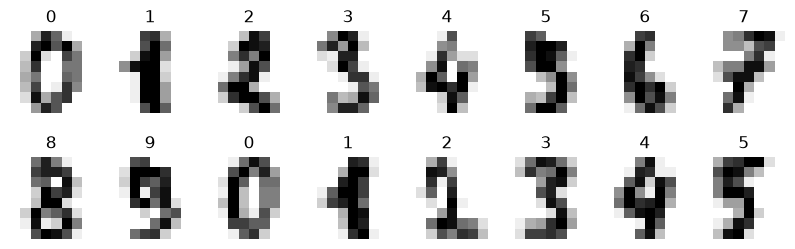

(1797, 64) (1797,) | classes : [0 1 2 3 4 5 6 7 8 9]


In [2]:
from sklearn.datasets import load_digits
chiffres = load_digits()
fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax, img, lab in zip(axes.ravel(), chiffres.images, chiffres.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab); ax.axis("off")
plt.show()
X = chiffres.data / 16.0
y = chiffres.target
print(X.shape, y.shape, "| classes :", np.unique(y))

## 🎯 Étape 2 — Découper
Même principe qu'avant : un jeu pour apprendre, un jeu de vérification jamais utilisé pendant l'apprentissage. Avec 10 classes, on **stratifie** pour que chaque chiffre soit représenté de façon équilibrée dans les deux jeux.

**À faire :** Découpez `X`, `y` en `X_train`, `X_test`, `y_train`, `y_test` : **25 % de test**, **stratifié**, `random_state=42`.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [4]:
# ✅ Contrôle (ne pas modifier)
controle(X_train.shape == (1347, 64) and X_test.shape == (450, 64), 'Découpage correct : 1347 / 450', 'Attendu (1347, 64) et (450, 64)')

✅ Découpage correct : 1347 / 450


## 🎯 Étape 3 — La référence
Comparez toujours à une méthode simple.

**À faire :** Entraînez une **régression logistique** (`max_iter=3000`) et stockez sa précision sur le test dans `acc_logistique`.

In [ ]:
from sklearn.linear_model import LogisticRegression

acc_logistique = LogisticRegression(max_iter=3000).fit(X_train, y_train).score(X_test, y_test)

In [7]:
# ✅ Contrôle (ne pas modifier)
controle(acc_logistique > 0.94, 'Référence : %.3f' % acc_logistique, 'Attendu plus de 0.94')

✅ Référence : 0.962


## 🎯 Étape 4 — Construire le réseau
Avec 10 classes, la sortie devient **10 neurones avec une activation `softmax`** : elle donne **10 probabilités qui totalisent 1** (une par chiffre). La perte devient **`sparse_categorical_crossentropy`** : la même idée que `binary_crossentropy`, pour plusieurs classes, avec des étiquettes données comme des **entiers** (0 à 9).

**À faire :** Construisez `modele` : entrée de 64, couches cachées de **64 puis 32 neurones (ReLU)**, sortie de **10 neurones softmax**. Compilez avec **adam**, **sparse_categorical_crossentropy**, métrique **accuracy**.

> 💡 **Indice** : Pourquoi 10 neurones en sortie ? Pensez au nombre de classes.

In [7]:
keras.utils.set_random_seed(42)
# TODO

modele = keras.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(10, activation='softmax')
])
modele.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [8]:
# ✅ Contrôle (ne pas modifier)
controle(modele.count_params() == 6570, 'Réseau correct : 6 570 paramètres', 'Attendu 6 570 paramètres, obtenu ' + str(modele.count_params()))

✅ Réseau correct : 6 570 paramètres


## Étape 5 — Avant l'entraînement : que répond le réseau ?
Un réseau non entraîné a des poids aléatoires. Il répond à peu près **au hasard** : les 10 probabilités sont proches, et leur somme fait **toujours 1**.

In [9]:
p = modele.predict(X_test[:1], verbose=0)[0]
print("probabilités :", np.round(p, 3))
print("somme        :", round(float(p.sum()), 3))

probabilités : [0.093 0.111 0.068 0.065 0.078 0.098 0.1   0.149 0.094 0.142]
somme        : 1.0


## 🎯 Étape 6 — Entraîner
Rien de nouveau ici : même procédure qu'aux TP précédents.

**À faire :** Entraînez `modele` : **40 epochs**, batch de 32, **20 % de validation**, sans affichage. Stockez dans `histoire`.

In [10]:
# TODO
histoire = modele.fit(X_train, y_train, epochs=40, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 91ms/step - accuracy: 0.3278 - loss: 2.1348 - val_accuracy: 0.4370 - val_loss: 1.9368
Epoch 2/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5227 - loss: 1.7096 - val_accuracy: 0.6222 - val_loss: 1.4740
Epoch 3/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7577 - loss: 1.2239 - val_accuracy: 0.8259 - val_loss: 1.0011
Epoch 4/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8505 - loss: 0.8015 - val_accuracy: 0.8556 - val_loss: 0.6869
Epoch 5/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8895 - loss: 0.5568 - val_accuracy: 0.8778 - val_loss: 0.5096
Epoch 6/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9136 - loss: 0.4168 - val_accuracy: 0.8889 - val_loss: 0.4055
Epoch 7/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9276 - loss: 0.3298 - val_accuracy: 0.9111 - val_loss: 0.3383
Epoch 8/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9434 - loss: 0.2720 - val_accuracy: 0.9222 - val_l

In [11]:
# ✅ Contrôle (ne pas modifier)
controle(len(histoire.history['loss']) == 40, '40 epochs effectués', 'Attendu 40 epochs')

✅ 40 epochs effectués


## Étape 7 — Les courbes
Les deux courbes montent-elles ensemble ? L'écart entre elles est-il grand ?

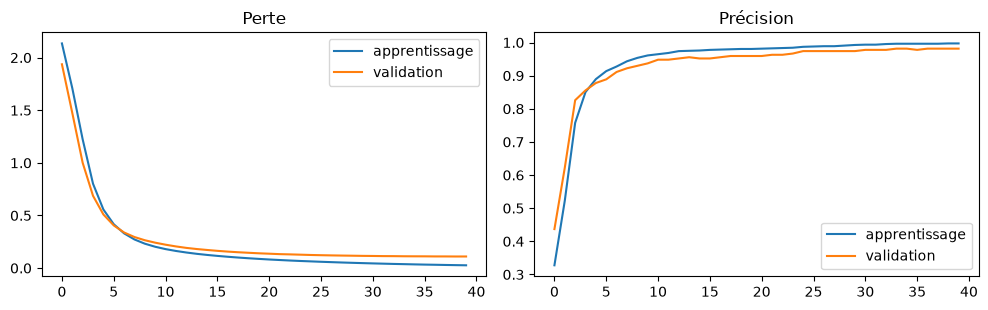

In [12]:
h = histoire.history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h["loss"], label="apprentissage"); ax[0].plot(h["val_loss"], label="validation"); ax[0].set_title("Perte"); ax[0].legend()
ax[1].plot(h["accuracy"], label="apprentissage"); ax[1].plot(h["val_accuracy"], label="validation"); ax[1].set_title("Précision"); ax[1].legend()
plt.tight_layout(); plt.show()

## 🎯 Étape 8 — Évaluer sur le test
Avec une sortie softmax, `predict` renvoie 10 probabilités par image. La **réponse** du réseau est la classe de **plus forte probabilité** : c'est `argmax`.

**À faire :** Calculez `y_pred` (la classe prédite pour chaque image de test), `acc` (part de bonnes réponses) et `matrice` (la matrice de confusion, 10 × 10). Comparez `acc` à `acc_logistique`.

> 💡 **Indice** : `np.argmax(..., axis=1)`. `confusion_matrix(vrais, prédits)`.

In [13]:
from sklearn.metrics import confusion_matrix
# TODO : y_pred, acc, matrice

y_pred = np.argmax(modele.predict(X_test), axis=1)
acc = np.mean(y_pred == y_test)
matrice = confusion_matrix(y_test, y_pred)

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step


In [14]:
# ✅ Contrôle (ne pas modifier)
controle(acc > 0.94 and matrice.shape == (10, 10) and matrice.sum() == 450, 'Évaluation correcte', 'Attendu : précision > 0.94, matrice 10 x 10 qui totalise 450')

✅ Évaluation correcte


In [17]:
print(f"Précision modèle : {acc:.2%} vs Précision logistique : {acc_logistique:.2%} => Gain de {acc - acc_logistique:.2%}")

Précision modèle : 97.78% vs Précision logistique : 96.22% => Gain de 1.56%


## Étape 9 — La matrice de confusion en image
La **diagonale** = les bonnes réponses. Tout ce qui est **hors diagonale** est une erreur : la ligne dit le vrai chiffre, la colonne ce que le réseau a répondu.

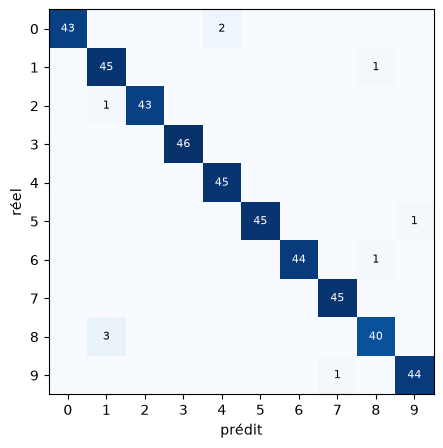

In [18]:
plt.figure(figsize=(6, 5)); plt.imshow(matrice, cmap="Blues")
for i in range(10):
    for j in range(10):
        if matrice[i, j]:
            plt.text(j, i, matrice[i, j], ha="center", va="center", fontsize=8, color="white" if matrice[i, j] > matrice.max() / 2 else "black")
plt.xlabel("prédit"); plt.ylabel("réel"); plt.xticks(range(10)); plt.yticks(range(10)); plt.show()

## 🎯 Étape 10 — Regarder les erreurs
Un bon réflexe : **regarder les exemples où le modèle se trompe**. On comprend souvent pourquoi.

**À faire :** Calculez `erreurs` (les **indices** des images mal classées). Affichez le nombre d'erreurs, les **3 confusions les plus fréquentes** (couples « vrai → prédit »), puis **6 images mal classées** avec leur vrai chiffre et la prédiction.

> 💡 **Indice** : `np.where(y_pred != y_test)[0]`. `Counter(zip(a, b)).most_common(3)`. `X_test[i].reshape(8, 8)` remet l'image en carré.

Nombre d'erreurs : 10


'Confusions les plus communes :'

[((np.int64(8), np.int64(1)), 3),
 ((np.int64(0), np.int64(4)), 2),
 ((np.int64(9), np.int64(7)), 1)]

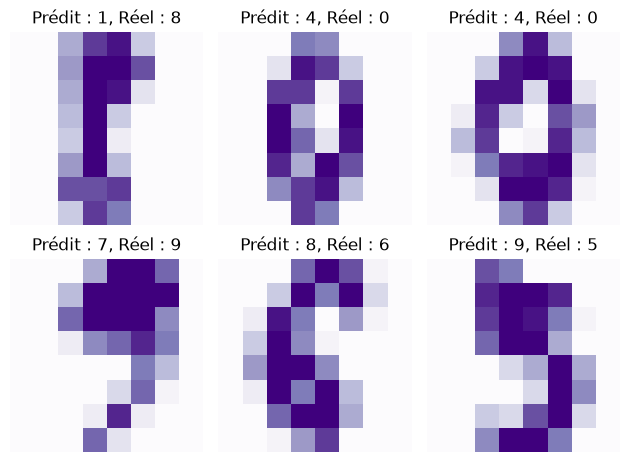

In [36]:
from collections import Counter
# TODO : erreurs, confusions fréquentes, 6 images mal classées
erreurs = np.where(y_pred != y_test)[0]
nb_erreurs = len(erreurs)
print(f"Nombre d'erreurs : {nb_erreurs}")

confusions = Counter(zip(y_test[erreurs], y_pred[erreurs])).most_common(3)
display("Confusions les plus communes :",confusions)

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(X_test[erreurs[i]].reshape(8, 8), cmap='Purples')
    plt.title(f"Prédit : {y_pred[erreurs[i]]}, Réel : {y_test[erreurs[i]]}")
    plt.axis('off')
plt.tight_layout() 
plt.show()

In [22]:
# ✅ Contrôle (ne pas modifier)
controle(len(erreurs) == int(np.sum(y_pred != y_test)), 'Liste des erreurs correcte (%d)' % len(erreurs), 'Vérifiez le calcul des indices d\'erreur')

✅ Liste des erreurs correcte (10)


### ✍️ Question
**Les erreurs vous paraissent-elles raisonnables ? Un humain se tromperait-il sur ces images ?**

*Votre réponse (2 à 4 lignes) :*

> Sur l'€chatillon d'image que j'ai, j'aurais pu en reconnaitre la moitié, l'erreur parait donc trés rainonnable.

### ✍️ Question
**Pourquoi une sortie softmax plutôt qu'une sigmoïde ici ? Que change `sparse_categorical_crossentropy` par rapport à `binary_crossentropy` ?**

*Votre réponse (2 à 4 lignes) :*

> Softmax : on a 10 classes mutuellement exclusives (un chiffre ne peut pas être 3 et 7). La sigmoïde ne sort qu'une probabilité indépendante (oui/non, TP2) ; la softmax répartit le total sur 10 neurones dont les probabilités somment à 1, et la prédiction est la classe la plus probable (argmax).

> Perte : sparse_categorical_crossentropy est la généralisation de binary_crossentropy à K classes; elle pénalise la probabilité attribuée à la bonne classe, avec des étiquettes en entiers (0–9, d'où « sparse ») plutôt que 0/1.

> Résumé : sigmoïde = 1 neurone, 2 classes, proba indépendante ; softmax = N neurones, N classes, probas concurrentes qui font 1.

## ✅ Ce qu'il faut retenir
- **Plusieurs classes** : sortie à **N neurones softmax** (N probabilités qui font 1), perte **sparse_categorical_crossentropy**.
- La réponse du réseau est la classe de **plus forte probabilité** (`argmax`).
- Une **image** peut entrer dans un réseau dense en étant **aplatie** en vecteur… mais on perd sa structure : c'est ce que le TP4 va corriger.
- **Regarder les erreurs** est aussi important que regarder la précision.